# Notebook 04 — PCA (Principal Component Analysis)

**Goal**: Reduce our 10 features to 2-3 dimensions without losing important information.

**What you'll learn:**
- What PCA does and why we need it
- Explained variance — how much information each component captures
- Visualizing high-dimensional data in 2D
- When PCA helps and when it doesn't

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

sns.set_theme(style='whitegrid')

# Load scaled data from notebook 03
X = pd.read_csv('../data/customers_processed.csv')
df_raw = pd.read_csv('../data/customers_raw.csv')  # for archetype labels (visualization only)

print(f'Feature matrix: {X.shape}')

Feature matrix: (1000, 10)


## What is PCA?

PCA finds new axes (called **principal components**) that capture the maximum variance in your data.

Think of it like this: if you have a cloud of points in 3D space, PCA finds the best 2D "shadow" (projection) that preserves as much of the cloud's shape as possible.

Why do we care?
1. **Visualization** — We can't plot 10 dimensions, but we can plot 2
2. **Noise reduction** — Lower-variance components often capture noise
3. **Removes redundancy** — Correlated features get merged into one component

## Step 1 — Fit PCA with all components

First we fit PCA keeping all 10 components, then look at how much variance each one explains.
This tells us how many components we actually need.

In [2]:
# Fit PCA keeping all components
pca_full = PCA(n_components=X.shape[1], random_state=42)
pca_full.fit(X)

# Explained variance per component
explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

print('Explained variance per component:')
for i, (ev, cv) in enumerate(zip(explained_var, cumulative_var)):
    print(f'  PC{i+1}: {ev*100:.1f}%  (cumulative: {cv*100:.1f}%)')

Explained variance per component:
  PC1: 58.6%  (cumulative: 58.6%)
  PC2: 16.0%  (cumulative: 74.6%)
  PC3: 6.7%  (cumulative: 81.3%)
  PC4: 5.2%  (cumulative: 86.5%)
  PC5: 4.0%  (cumulative: 90.6%)
  PC6: 3.7%  (cumulative: 94.2%)
  PC7: 2.8%  (cumulative: 97.0%)
  PC8: 2.0%  (cumulative: 99.0%)
  PC9: 0.8%  (cumulative: 99.8%)
  PC10: 0.2%  (cumulative: 100.0%)


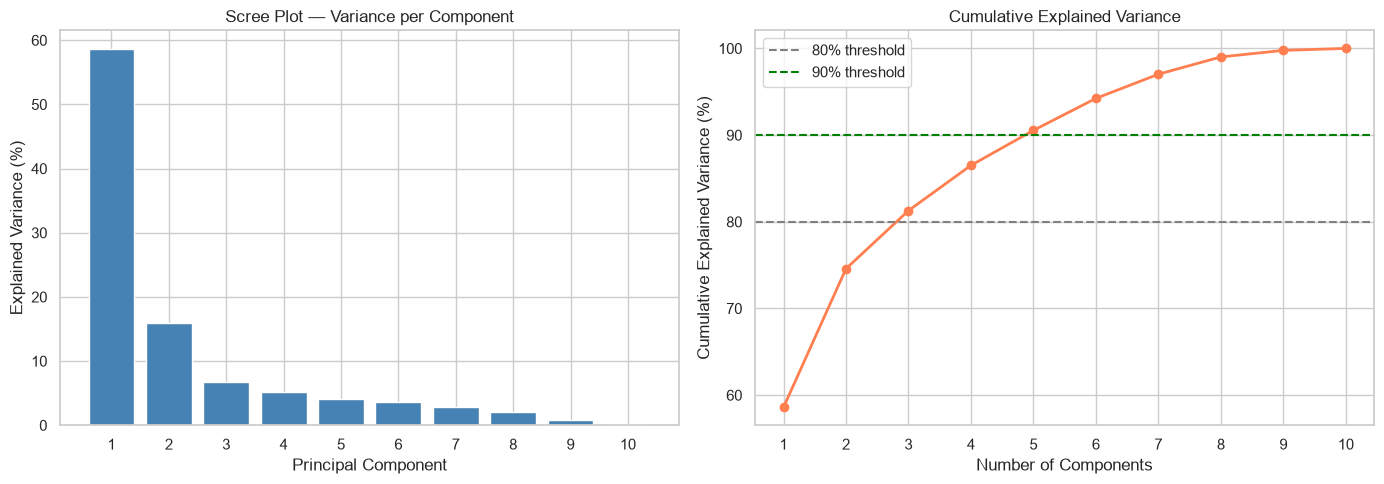

In [3]:
# Scree plot — visualize explained variance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Individual variance per component
axes[0].bar(range(1, len(explained_var)+1), explained_var * 100,
            color='steelblue', edgecolor='white')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_title('Scree Plot — Variance per Component')
axes[0].set_xticks(range(1, len(explained_var)+1))

# Cumulative variance
axes[1].plot(range(1, len(cumulative_var)+1), cumulative_var * 100,
             marker='o', color='coral', linewidth=2)
axes[1].axhline(y=80, color='gray', linestyle='--', label='80% threshold')
axes[1].axhline(y=90, color='green', linestyle='--', label='90% threshold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance (%)')
axes[1].set_title('Cumulative Explained Variance')
axes[1].set_xticks(range(1, len(cumulative_var)+1))
axes[1].legend()

plt.tight_layout()
plt.show()

**How many components to keep?**
Common rules:
- Keep components until cumulative variance > 80-90%
- Look for the "elbow" in the scree plot — the point where adding more components gives diminishing returns

For clustering + visualization, we'll use **2 components** (easy to plot).
For the actual clustering model, we'll use enough to capture ~85% variance.

## Step 2 — PCA for visualization (2 components)

In [4]:
# 2D PCA for visualization
pca_2d = PCA(n_components=2, random_state=42)
X_2d = pca_2d.fit_transform(X)

print(f'2 components explain {pca_2d.explained_variance_ratio_.sum()*100:.1f}% of variance')

# Create a DataFrame for easy plotting
df_2d = pd.DataFrame(X_2d, columns=['PC1', 'PC2'])
df_2d['archetype'] = df_raw['archetype'].values

df_2d.head()

2 components explain 74.6% of variance


,PC1,PC2,archetype
0,3.114770,0.478126,high_earner
1,1.265865,-0.461316,stable_saver
2,-2.005848,1.985860,debt_stressed
3,4.378576,0.397987,high_earner
4,-1.734716,-1.320397,young_spender


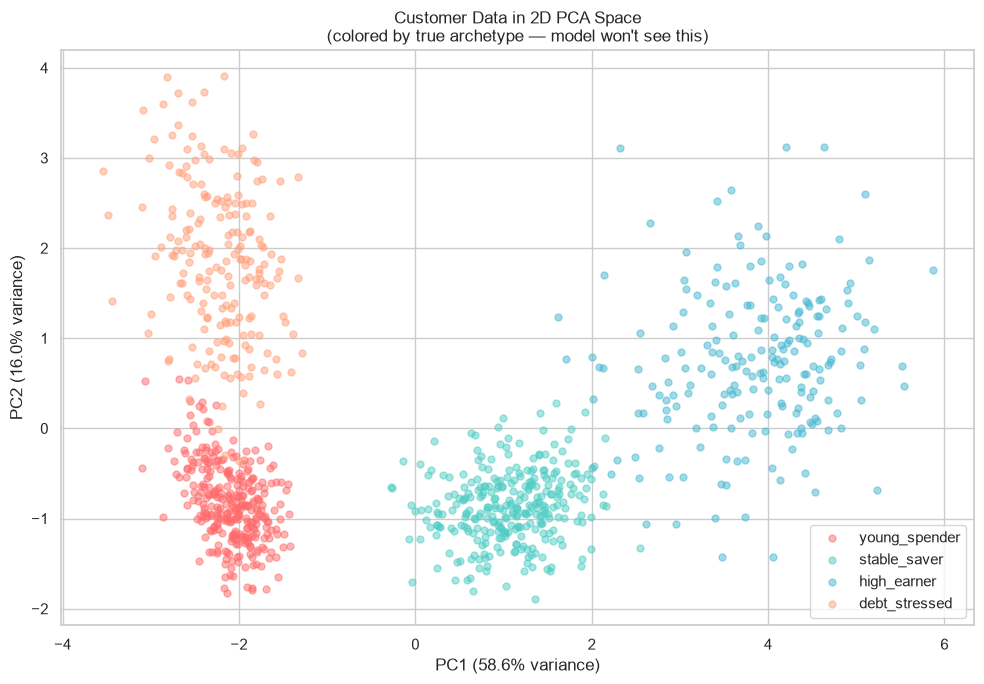

In [5]:
# Plot 2D projection colored by archetype
archetype_colors = {
    'young_spender': '#FF6B6B',
    'stable_saver':  '#4ECDC4',
    'high_earner':   '#45B7D1',
    'debt_stressed': '#FFA07A',
}

plt.figure(figsize=(10, 7))
for archetype, color in archetype_colors.items():
    subset = df_2d[df_2d['archetype'] == archetype]
    plt.scatter(subset['PC1'], subset['PC2'],
                c=color, label=archetype, alpha=0.5, s=25)

plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)')
plt.title('Customer Data in 2D PCA Space\n(colored by true archetype — model won\'t see this)')
plt.legend()
plt.tight_layout()
plt.show()

**What you're seeing**: 10 features compressed into 2 dimensions. The clusters are somewhat visible — this means KMeans should be able to find them!

## Step 3 — What do the components represent?

PCA components are weighted combinations of original features.
The **loadings** tell us which original features contributed most to each component.

In [6]:
# Component loadings
loadings = pd.DataFrame(
    pca_2d.components_.T,
    index=X.columns,
    columns=['PC1', 'PC2']
).round(3)

print('Feature loadings (contribution to each component):')
print(loadings.to_string())

Feature loadings (contribution to each component):
                         PC1    PC2
age                    0.271  0.236
annual_income          0.372  0.056
monthly_spending       0.295  0.387
savings_balance        0.381  0.056
credit_score           0.361 -0.198
loan_amount           -0.084  0.690
num_existing_products  0.359  0.028
months_as_customer     0.325  0.154
spending_ratio        -0.250  0.492
savings_ratio          0.349 -0.080


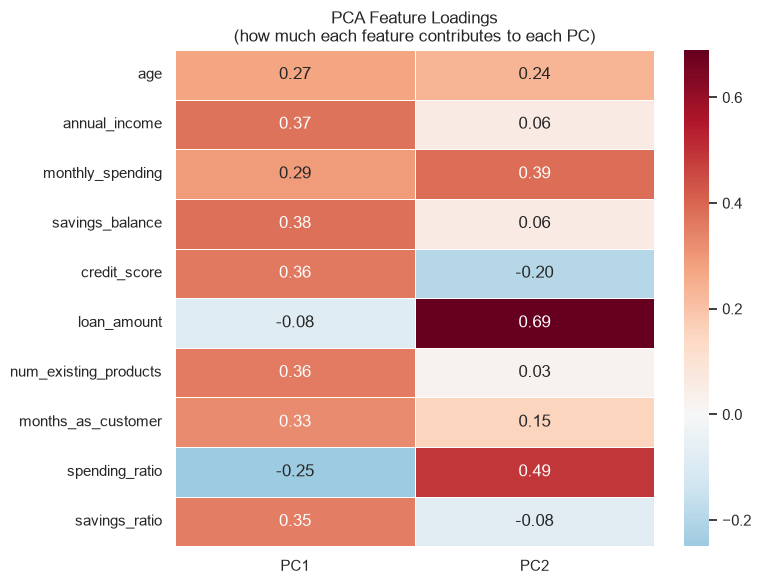

In [7]:
# Visualize loadings as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            linewidths=0.5)
plt.title('PCA Feature Loadings\n(how much each feature contributes to each PC)')
plt.tight_layout()
plt.show()

**Interpretation:**
- **PC1** (the main axis): Large loadings from income, savings, credit score → this axis separates **wealthy vs. not wealthy**
- **PC2** (secondary axis): Large loadings from spending, loan → this axis separates **high-debt/spending vs. conservative**

## Step 4 — Save PCA output for clustering

In [8]:
import joblib

# Decide how many components to keep for clustering (aim for ~85% variance)
n_components_for_clustering = int(np.argmax(cumulative_var >= 0.85)) + 1
print(f'Using {n_components_for_clustering} components for clustering ({cumulative_var[n_components_for_clustering-1]*100:.1f}% variance)')

pca_cluster = PCA(n_components=n_components_for_clustering, random_state=42)
X_pca = pca_cluster.fit_transform(X)

# Save for notebook 05
pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(n_components_for_clustering)]).to_csv('../data/customers_pca.csv', index=False)
pd.DataFrame(X_2d, columns=['PC1', 'PC2']).to_csv('../data/customers_pca_2d.csv', index=False)
joblib.dump(pca_cluster, '../data/pca_model.pkl')

print('Saved PCA outputs to data/')

Using 4 components for clustering (86.5% variance)
Saved PCA outputs to data/


## Checkpoint — What you learned

| Concept | Takeaway |
|---|---|
| PCA | Finds new axes that maximize variance, compresses dimensions |
| Explained variance | How much info each component keeps |
| Scree plot | Helps decide how many components to keep |
| Loadings | Which original features drive each component |
| 2D projection | Lets us visualize high-dimensional data |

**Next up: Notebook 05 — Clustering**
We'll apply KMeans to the PCA-reduced data, find the optimal K, and evaluate the clusters.